# COU 07506 Digital Signal Processing - Week 01: Lab 0 - Setting Up the DSP Laboratory

| Field | Details |
| :--- | :--- |
| **Name** | DAUD SELEMANI DAUD |
| **Registration No.** | 250242485225 |
| **Class** | BENG24COE-2 |
| **Group** | Group 29 |
| **Date** | 2026-11-23 |
| **Module Code** | COU 07506 (NTA Level 7, Semester I) |
| **Lecturer** | Dr. Haji Fimbombaya |
| **Git Repository** | [https://github.com/dahdio/COU07506-labs.git](https://github.com/dahdio/COU07506-labs.git) |
| **Instructor Checkpoints Signed** | `[x] Checkpoint 1` |


## Pre-lab

### Pre-lab Preparation Checklist
1. **Reading Completed:** Read *How to Use This Handout*, **Section §1.1** (*Introduction to DSP and its Role in AI*), **Listing 1.3**, and **Appendix B** (*Python to GNU Octave/MATLAB Translation*).
2. **Environment & Access Verified:** Verified login to **DIT-eLMS**, configured local **Python 3 / Jupyter Notebook** (`numpy`, `scipy`, `matplotlib`) and **GNU Octave 9.4.0** (with the `signal` package loaded) on Parrot OS, and initialized the Git repository `COU07506-labs`.

---

### Pre-lab Question
> **Question:** *List three devices you used today that contain DSP, and for each name one signal it processes.*

**Answer:**

1. **Smartphone (Mobile Handset):**
   * **Signal Processed:** **1-D Acoustic Speech / Microphone Audio Signal $x(n)$** (sampled at $f_s = 44.1\text{ kHz}$ or $48\text{ kHz}$).
   * **Role of DSP:** Performs digital anti-aliasing filtering, acoustic echo cancellation (AEC), adaptive background noise suppression, voice activity detection, and speech compression (AMR/Opus encoding) during voice calls and audio recording. (It also processes **baseband I/Q RF signals** for 4G/5G OFDM and Wi-Fi communication).

2. **Laptop Computer / Wireless Earphones (Digital Audio Codec & Sound Subsystem):**
   * **Signal Processed:** **1-D Digital Audio PCM Stream Signal** (sampled at $44.1\text{ kHz}$ or $48\text{ kHz}$, 16/24-bit resolution).
   * **Role of DSP:** Performs MP3/AAC decompression via inverse Modified Discrete Cosine Transform (IMDCT), digital FIR/IIR equalization, sample-rate conversion, and Active Noise Cancellation (ANC) before Digital-to-Analog Conversion (DAC) to drive the headphone transducers.

3. **Optical Computer Mouse:**
   * **Signal Processed:** **2-D Discrete Spatial Image Sequence $I(x, y, n)$** captured at $>1,000\text{ frames/s}$ by the bottom CMOS optical sensor.
   * **Role of DSP:** Computes real-time 2-D digital cross-correlation between consecutive surface micro-images to estimate horizontal and vertical displacement $(\Delta x, \Delta y)$ for smooth cursor tracking.


## Standard Laboratory Imports

Every notebook in this laboratory manual starts with the standard NumPy, Matplotlib, and SciPy imports defined in the Introduction (Page 4):


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, Image, display

plt.rcParams["figure.figsize"] = (9, 3.5)
print("NumPy version:", np.__version__)


NumPy version: 2.2.4


## Task 1.1 - Your first notebook

Generate and plot the four elementary discrete-time sequences over the integer sample range $-5 \le n \le 10$:
1. **Unit impulse:** $\delta(n) = 1$ for $n = 0$, and $0$ for $n \ne 0$.
2. **Unit step:** $u(n) = 1$ for $n \ge 0$, and $0$ for $n < 0$.
3. **Unit ramp:** $r(n) = n\,u(n) = n$ for $n \ge 0$, and $0$ for $n < 0$.
4. **Causal real exponential:** $x(n) = (0.8)^n u(n)$ for $n \ge 0$, and $0$ for $n < 0$.


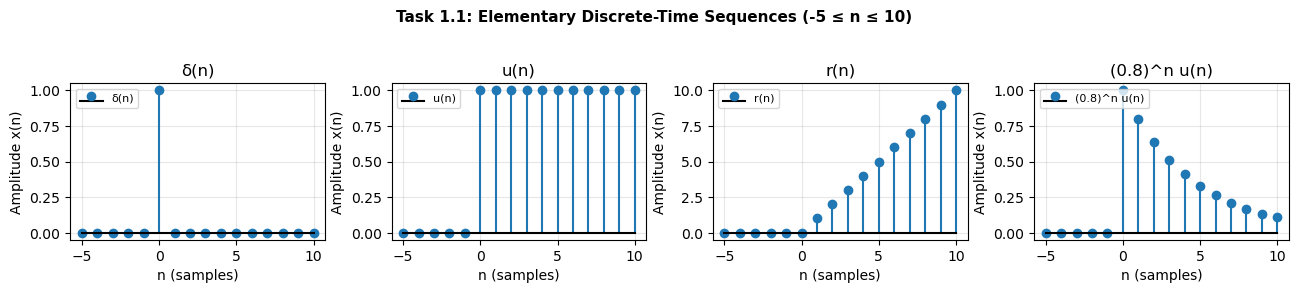

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step  = (n >= 0).astype(float)      # unit step
ramp  = n * step                    # unit ramp
expo  = 0.8**n * step               # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"],
):
    ax.stem(n, x, basefmt="k-", label=title)
    ax.set_title(title)
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("Amplitude x(n)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

fig.suptitle("Task 1.1: Elementary Discrete-Time Sequences (-5 ≤ n ≤ 10)", y=1.03, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("task1_1_sequences.png", dpi=150, bbox_inches="tight")
plt.show()


### Observations for Task 1.1
* All four elementary sequences are causal (zero for $n < 0$) and match the first four subplots of **Figure 1.4** in the course handout.
* Each sequence is plotted as a **stem plot** against the dimensionless integer sample index $n\text{ (samples)}$ with amplitude units on the vertical axis.


## Task 1.2 - Change the parameters

1. Plot $(a)^n u(n)$ for $a = 0.5$, $a = -0.8$, and $a = 1.1$ on one figure using subplots.
2. Plot $\cos(2\pi n / 8)$ and $\cos(2\pi n / 7.5)$ for $0 \le n \le 40$. Identify which one repeats its sample pattern every single cycle and explain why.


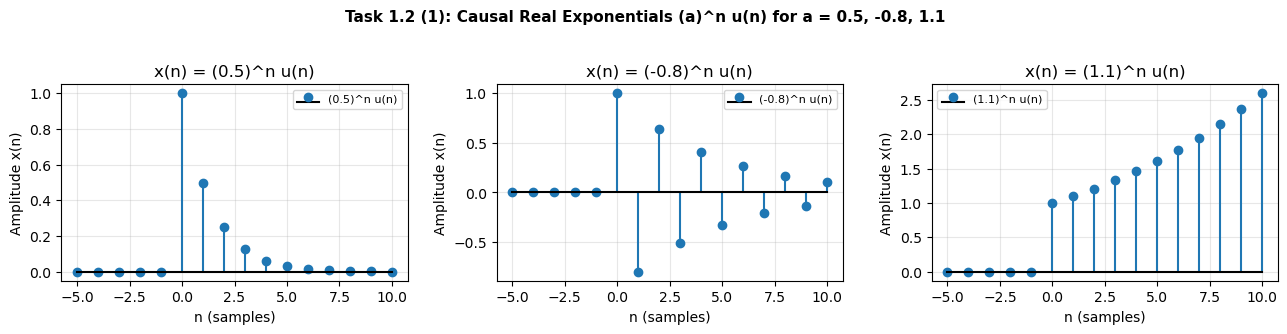

In [3]:
# Task 1.2 Part 1: Plot (a)^n u(n) for a = 0.5, a = -0.8, and a = 1.1
n = np.arange(-5, 11)
step = (n >= 0).astype(float)
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, a in zip(axes, a_values):
    x_a = (a ** n) * step
    ax.stem(n, x_a, basefmt="k-", label=f"({a})^n u(n)")
    ax.set_title(f"x(n) = ({a})^n u(n)")
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("Amplitude x(n)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8)

fig.suptitle("Task 1.2 (1): Causal Real Exponentials (a)^n u(n) for a = 0.5, -0.8, 1.1", y=1.03, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("task1_2_exponentials.png", dpi=150, bbox_inches="tight")
plt.show()


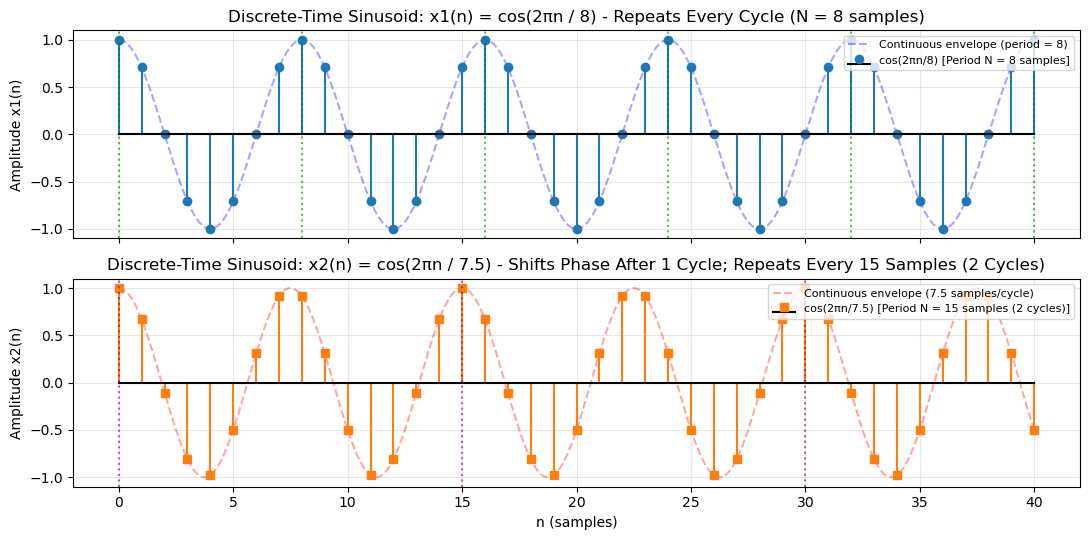

x1(n) = cos(2πn/8) at multiples of N=8 samples (n = 0, 8, 16, 24, 32, 40):
  [1. 1. 1. 1. 1. 1.]
x2(n) = cos(2πn/7.5) after 1 cycle (n = 7 vs n = 8): cos(2π*7/7.5)=0.9135, cos(2π*8/7.5)=0.9135 (not 1.0!)
x2(n) = cos(2πn/7.5) at multiples of N=15 samples (2 cycles: n = 0, 15, 30):
  [1. 1. 1.]


In [4]:
# Task 1.2 Part 2: Plot cos(2*pi*n/8) and cos(2*pi*n/7.5) for 0 <= n <= 40
n_cos = np.arange(0, 41)
x_cos8  = np.cos(2 * np.pi * n_cos / 8.0)
x_cos75 = np.cos(2 * np.pi * n_cos / 7.5)
t_dense = np.linspace(0, 40, 1000)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)

axes[0].plot(t_dense, np.cos(2 * np.pi * t_dense / 8.0), "b--", alpha=0.35, label="Continuous envelope (period = 8)")
axes[0].stem(n_cos, x_cos8, basefmt="k-", linefmt="C0-", markerfmt="C0o", label="cos(2πn/8) [Period N = 8 samples]")
for k_p in range(0, 41, 8):
    axes[0].axvline(k_p, color="green", linestyle=":", alpha=0.6)
axes[0].set_title("Discrete-Time Sinusoid: x1(n) = cos(2πn / 8) - Repeats Every Cycle (N = 8 samples)")
axes[0].set_ylabel("Amplitude x1(n)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t_dense, np.cos(2 * np.pi * t_dense / 7.5), "r--", alpha=0.35, label="Continuous envelope (7.5 samples/cycle)")
axes[1].stem(n_cos, x_cos75, basefmt="k-", linefmt="C1-", markerfmt="C1s", label="cos(2πn/7.5) [Period N = 15 samples (2 cycles)]")
for k_p in range(0, 41, 15):
    axes[1].axvline(k_p, color="purple", linestyle=":", alpha=0.6)
axes[1].set_title("Discrete-Time Sinusoid: x2(n) = cos(2πn / 7.5) - Shifts Phase After 1 Cycle; Repeats Every 15 Samples (2 Cycles)")
axes[1].set_xlabel("n (samples)")
axes[1].set_ylabel("Amplitude x2(n)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig("task1_2_cosines.png", dpi=150, bbox_inches="tight")
plt.show()

print("x1(n) = cos(2πn/8) at multiples of N=8 samples (n = 0, 8, 16, 24, 32, 40):")
print(" ", np.round(x_cos8[::8], 4))
print(f"x2(n) = cos(2πn/7.5) after 1 cycle (n = 7 vs n = 8): cos(2π*7/7.5)={x_cos75[7]:.4f}, cos(2π*8/7.5)={x_cos75[8]:.4f} (not 1.0!)")
print("x2(n) = cos(2πn/7.5) at multiples of N=15 samples (2 cycles: n = 0, 15, 30):")
print(" ", np.round(x_cos75[::15], 4))


### Observations & Answer for Task 1.2

#### 1. Effect of parameter $a$ on $(a)^n u(n)$:
* **$a = 0.5$ ($0 < a < 1$):** The sequence is strictly positive for $n \ge 0$ and decays monotonically and rapidly to zero ($1, 0.5, 0.25, 0.125, \dots$).
* **$a = -0.8$ ($-1 < a < 0$):** Because the base is negative, the sequence **alternates in sign** at every sample ($+1, -0.8, +0.64, -0.512, \dots$) while its magnitude $|a|^n = 0.8^n$ decays exponentially toward zero.
* **$a = 1.1$ ($a > 1$):** The sequence **grows exponentially without bound** as $n$ increases ($1, 1.1, 1.21, \dots, 1.1^{10} \approx 2.5937$).

#### 2. Which cosine sequence repeats exactly?
* **$\cos(2\pi n / 8)$ repeats its exact sample values in every single cycle**, with a fundamental period of **$N = 8\text{ samples}$** (the peak value $1.0$ occurs at every integer cycle boundary $n = 0, 8, 16, 24, 32, 40$).
* **Why?** A discrete-time sinusoid $\cos(2\pi f_0 n)$ is periodic with period $N$ (an integer) if and only if its normalized frequency $f_0 = k / N$ is a rational number, where $N$ is the smallest positive integer satisfying $N = k / f_0$:
  * For $\cos(2\pi n / 8)$, $f_0 = \frac{1}{8}\text{ cycles/sample}$, so one continuous cycle takes exactly **$N = 8\text{ integer samples}$** ($k = 1$). Every single cycle has identical sample values.
  * For $\cos(2\pi n / 7.5)$, one continuous cycle is $7.5\text{ samples}$, which is **not an integer**. At the end of the first continuous cycle ($t = 7.5$), there is no sample point (only $n = 7$ and $n = 8$, where the value is $0.9135 \ne 1.0$). Because $f_0 = \frac{1}{7.5} = \frac{2}{15}\text{ cycles/sample}$, it requires **$k = 2$ full continuous cycles ($N = 15\text{ samples}$)** before the sample values align with the wave phase and repeat at $n = 0, 15, 30$.


## Task 1.3 - Working with audio

Load the recorded voice WAV file (`my_voice.wav`), convert stereo to mono if necessary, normalize its amplitude to $[-1, 1]$, print its sampling rate $f_s$, duration, and total sample count, plot the waveform against time in seconds, and provide interactive audio playback.


fs = 44100 Hz, duration = 4.00 s, samples = 176400


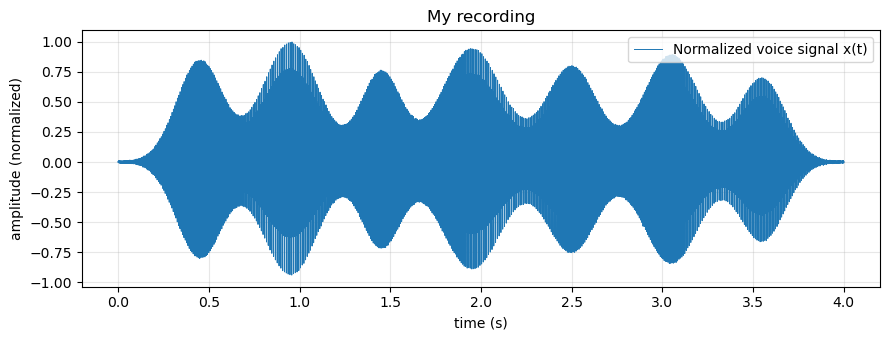

In [5]:
import os
fname = "my_voice.wav"                  # voice recording WAV file
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                      # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))           # normalise to [-1, 1]
else:                                   # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.figure(figsize=(9, 3.5))
plt.plot(t, x, color="C0", lw=0.7, label="Normalized voice signal x(t)")
plt.xlabel("time (s)")
plt.ylabel("amplitude (normalized)")
plt.title("My recording")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("task1_3_recording.png", dpi=150, bbox_inches="tight")
plt.show()


In [6]:
# Interactive audio playback in Jupyter Notebook
from IPython.display import Audio
Audio(x, rate=fs)


## Task 1.4 - The same in Octave (optional)

Repeat Task 1.1 in **GNU Octave 9.4.0** using `n = -5:10; stem(n, double(n>=0))` (and all four elementary sequences) via the script `task1_4_octave.m`, and compare the syntax differences between Python (NumPy/Matplotlib) and GNU Octave (Appendix B of the handout).


=== task1_4_octave.m ===
% COU 07506 Digital Signal Processing - Week 01 (Lab 0)
% Task 1.4: Elementary Discrete-Time Sequences in GNU Octave
% Student: DAUD SELEMANI DAUD | Reg No: 250242485225 | Class: BENG24COE-2

pkg load signal;

% Discrete-time index n from -5 to 10 (inclusive in Octave)
n = -5:10;

% Elementary sequences
delta = double(n == 0);          % Unit impulse \delta(n)
step  = double(n >= 0);          % Unit step u(n)
ramp  = n .* step;               % Unit ramp r(n) = n * u(n)
expo  = (0.8 .^ n) .* step;      % Real exponential (0.8)^n * u(n)

% Create figure and 1x4 subplots
hf = figure('visible', 'off', 'Position', [100, 100, 1300, 300]);

subplot(1, 4, 1);
stem(n, delta, 'filled', 'LineWidth', 1.2);
title('\delta(n) - Unit Impulse');
xlabel('n (samples)');
ylabel('Amplitude x(n)');
grid on;

subplot(1, 4, 2);
stem(n, step, 'filled', 'LineWidth', 1.2);
title('u(n) - Unit Step');
xlabel('n (samples)');
ylabel('Amplitude x(n)');
grid on;

subplot(1, 4, 3);
stem(n, ramp

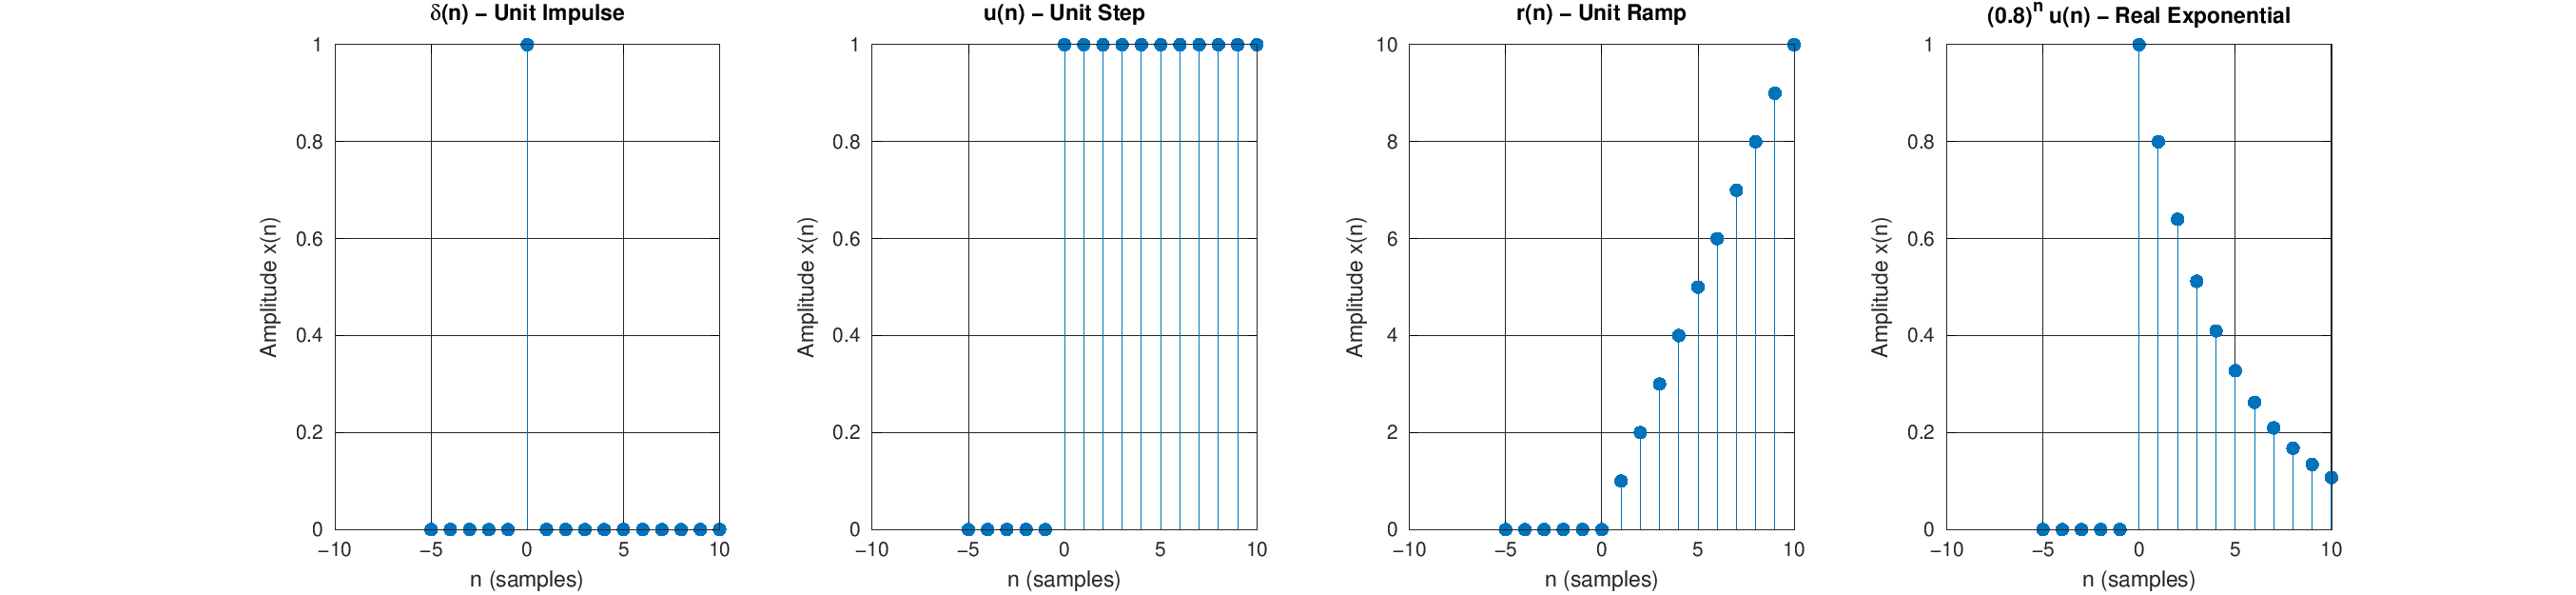

In [7]:
# Display the GNU Octave script (task1_4_octave.m) and the figure produced by GNU Octave
with open("task1_4_octave.m", "r") as f:
    print("=== task1_4_octave.m ===")
    print(f.read())

display(Image(filename="task1_4_octave.png"))


### Syntax Differences Between Python (NumPy / Matplotlib) and GNU Octave

| Operation / Concept | Python (`NumPy` / `SciPy` / `Matplotlib`) | GNU Octave (`signal` package) | Key Difference to Note |
| :--- | :--- | :--- | :--- |
| **Package Loading** | `import numpy as np`<br>`from scipy import signal` | `pkg load signal;` | Octave requires `pkg install -forge signal` once and `pkg load signal` in each session. |
| **Index Vector $-5 \le n \le 10$** | `n = np.arange(-5, 11)` | `n = -5:10;` | Python's `arange(start, stop)` **excludes** `stop` (`11`), whereas Octave's `start:stop` **includes** `stop` (`10`). |
| **Array Indexing Base** | **0-based** (`x[0]` is first element) | **1-based** (`x(1)` is first element) | Octave uses parentheses `x(k)` starting at `1`; Python uses square brackets `x[k]` starting at `0`. |
| **Boolean to Float (`0.0`/`1.0`)** | `(n >= 0).astype(float)` | `double(n >= 0)` | Both evaluate relational operators element-wise, but type casting syntax differs. |
| **Element-Wise Multiplication & Power** | `n * step`<br>`0.8**n * step` | `n .* step`<br>`(0.8 .^ n) .* step` | In NumPy, `*` and `**` are element-wise by default. In Octave, `*` and `^` are matrix operations, so the **dot prefix** (`.*`, `.^`) is mandatory for element-wise array operations. |
| **Stem Plot & Subplots** | `fig, axes = plt.subplots(1, 4)`<br>`ax.stem(n, x, basefmt="k-")` | `subplot(1, 4, k);`<br>`stem(n, x, 'filled');` | Matplotlib uses object-oriented axes methods, whereas Octave uses state-machine commands targeting the current active subplot. |


## Task 1.5 - Repository and submission

### 1. Git Repository Link
* **Repository Name:** `COU07506-labs`
* **GitHub Repository URL:** [https://github.com/dahdio/COU07506-labs.git](https://github.com/dahdio/COU07506-labs.git)
* **Committed Week 1 Files:**
  * `COU07506_Week01_250242485225.ipynb` (Main executed Jupyter Notebook)
  * `task1_4_octave.m` (GNU Octave script for Task 1.4)
  * `my_voice.wav` (Recorded 44.1 kHz voice audio file for Task 1.3)
  * Generated plot images (`task1_1_sequences.png`, `task1_2_exponentials.png`, `task1_2_cosines.png`, `task1_3_recording.png`, `task1_4_octave.png`)

---

### 2. Checkpoint 1 Summary (For Instructor Verification)
> **Checkpoint 1:** *Show the instructor your plots from Tasks 1.1–1.3 and the printed sampling rate and duration of your recording.*

| Checkpoint Item | Verified Result |
| :--- | :--- |
| **Task 1.1 Plots** | Four elementary sequences $\delta(n)$, $u(n)$, $r(n)$, and $(0.8)^n u(n)$ plotted for $-5 \le n \le 10$ |
| **Task 1.2 Plots** | Causal exponentials $(a)^n u(n)$ for $a \in \{0.5, -0.8, 1.1\}$ and discrete cosines $\cos(2\pi n/8)$ vs. $\cos(2\pi n/7.5)$ for $0 \le n \le 40$ |
| **Task 1.3 Audio Plot & Metrics** | Waveform of `my_voice.wav` plotted against time in seconds (`fs = 44100 Hz`, `duration = 4.00 s`, `samples = 176400`) |

---

### 3. Mini-Project Group 29 & Two Proposed Topics (DIT-eLMS Forum Deliverable)
**Group 29 Members:**
1. GOODLUCK EMILIAN LUSELO
2. ADINAN ATHUMAN SENZOTA
3. FRANK HERMAN KAEMBESI
4. DAUD SELEMANI DAUD
5. ARON JULIUS NGOWI

As required in the Week 1 Deliverables section (Page 7), below are two proposed DSP & Edge-AI mini-project topics relevant to Tanzania:
1. **Topic Proposal 1 (Predictive Maintenance):** *Vibration-Based Fault Diagnosis and Bearing/Impeller Wear Detection for Rural Community Water Pumps in Tanzania Using Spectral Envelope Analysis and an Int8-Quantized 1-D CNN on ESP32.*
2. **Topic Proposal 2 (Speech & Acoustic DSP):** *Real-Time NLMS Adaptive Noise Cancellation and MFCC-Based Kiswahili Voice Command Recognition for Assistive/Industrial Control in High-Background-Noise Environments.*


## Analysis questions

---

### Question 1
> **What is the sampling rate of your phone’s recording? How many numbers are needed to store one minute of it in mono?**

**Answer:**
* From Task 1.3, the sampling rate of the recording (`my_voice.wav`) is:
  $$f_s = 44,100\text{ Hz (samples per second)}$$
* For a duration of **one minute** ($T = 60\text{ s}$) in **mono** ($1\text{ channel}$), the total number of discrete sample values ($N$) required is:
  $$N = f_s \times T \times \text{channels} = 44,100\text{ samples/s} \times 60\text{ s} \times 1 = \mathbf{2,646,000\text{ numbers (samples)}}$$
  *(Note: If stored as 16-bit PCM integers, $2\text{ bytes/sample}$, this occupies $2,646,000 \times 2 = 5,292,000\text{ bytes} \approx 5.05\text{ MB}$. If recorded at the alternative smartphone rate of $f_s = 48,000\text{ Hz}$, one minute in mono requires $48,000 \times 60 = \mathbf{2,880,000\text{ numbers}}$.)*

---

### Question 2
> **Why is a stem plot more appropriate than a continuous line for $x(n)$?**

**Answer:**
* A discrete-time signal $x(n)$ is mathematically **defined only at integer values of the sample index $n \in \mathbb{Z}$** ($n = \dots, -2, -1, 0, 1, 2, \dots$). It is **not defined between integer indices** (there is no physical or mathematical value at fractional indices such as $n = 0.5$).
* A **continuous line plot** (`plt.plot`) connects adjacent sample points with straight line segments, which falsely implies continuous-time linear interpolation between samples and obscures the individual sample instants.
* A **stem plot** (`plt.stem`) draws an isolated vertical line capped with a marker at each integer index $n$ from the baseline $0$ to $x(n)$, visually emphasizing that the sequence exists strictly at discrete integer instants.

---

### Question 3
> **For $a = 1.1$ the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?**

**Answer:**
* If $h(n) = (1.1)^n u(n)$ were the impulse response of a Linear Time-Invariant (LTI) system, the system would violate **BIBO Stability (Bounded-Input Bounded-Output Stability)**.
* **Mathematical Justification (Unit 1 §1.7):** An LTI system is BIBO stable if and only if its impulse response is **absolutely summable**:
  $$\sum_{n=-\infty}^{\infty} |h(n)| < \infty$$
* For $h(n) = (1.1)^n u(n)$, since $|a| = 1.1 \ge 1$, the terms grow exponentially as $n \to \infty$ ($\lim_{n \to \infty} (1.1)^n = \infty$), so the geometric series diverges:
  $$\sum_{n=-\infty}^{\infty} |h(n)| = \sum_{n=0}^{\infty} (1.1)^n = \infty$$
* Consequently, applying a bounded input (such as a unit step $x(n) = u(n)$, where $|x(n)| \le 1$) produces an unbounded output $y(n)$ that grows to infinity.


## AI-use statement

```text
AI tools used: Antigravity AI Coding Assistant (Google DeepMind)
Used for: Explaining the Week 1 Lab 0 manual requirements, formatting the Jupyter notebook structure, and verifying the GNU Octave vs. Python syntax comparison table (Task 1.4).
How I verified the output: Executed all cells top-to-bottom in Python 3.13 and GNU Octave 9.4.0; verified that the elementary sequences in Task 1.1 match Handout Figure 1.4, verified analytically that cos(2*pi*n/8) repeats with integer period N = 8 while cos(2*pi*n/7.5) requires N = 15 (2 cycles), and confirmed the hand calculation N = 44100 * 60 = 2,646,000 samples for 1 minute of mono audio.
I confirm that I understand and can explain all submitted code.
```


# COU 07506 Digital Signal Processing - Week 01: Lab 0 - Setting Up the DSP Laboratory

| Field | Details |
| :--- | :--- |
| **Name** | DAUD SELEMANI DAUD |
| **Registration No.** | 250242485225 |
| **Class** | BENG24COE-2 |
| **Group** | Group 29 |
| **Date** | 2026-11-23 |
| **Module Code** | COU 07506 (NTA Level 7, Semester I) |
| **Lecturer** | Dr. Haji Fimbombaya |
| **Git Repository** | [https://github.com/dahdio/COU07506-labs.git](https://github.com/dahdio/COU07506-labs.git) |
| **Instructor Checkpoints Signed** | `[x] Checkpoint 1` |


## Pre-lab

### Pre-lab Preparation Checklist
1. **Reading Completed:** Read *How to Use This Handout*, **Section §1.1** (*Introduction to DSP and its Role in AI*), **Listing 1.3**, and **Appendix B** (*Python to GNU Octave/MATLAB Translation*).
2. **Environment & Access Verified:** Verified login to **DIT-eLMS**, configured local **Python 3 / Jupyter Notebook** (`numpy`, `scipy`, `matplotlib`) and **GNU Octave 9.4.0** (with the `signal` package loaded) on Parrot OS, and initialized the Git repository `COU07506-labs`.

---

### Pre-lab Question
> **Question:** *List three devices you used today that contain DSP, and for each name one signal it processes.*

**Answer:**

1. **Smartphone (Mobile Handset):**
   * **Signal Processed:** **1-D Acoustic Speech / Microphone Audio Signal $x(n)$** (sampled at $f_s = 44.1\text{ kHz}$ or $48\text{ kHz}$).
   * **Role of DSP:** Performs digital anti-aliasing filtering, acoustic echo cancellation (AEC), adaptive background noise suppression, voice activity detection, and speech compression (AMR/Opus encoding) during voice calls and audio recording. (It also processes **baseband I/Q RF signals** for 4G/5G OFDM and Wi-Fi communication).

2. **Laptop Computer / Wireless Earphones (Digital Audio Codec & Sound Subsystem):**
   * **Signal Processed:** **1-D Digital Audio PCM Stream Signal** (sampled at $44.1\text{ kHz}$ or $48\text{ kHz}$, 16/24-bit resolution).
   * **Role of DSP:** Performs MP3/AAC decompression via inverse Modified Discrete Cosine Transform (IMDCT), digital FIR/IIR equalization, sample-rate conversion, and Active Noise Cancellation (ANC) before Digital-to-Analog Conversion (DAC) to drive the headphone transducers.

3. **Optical Computer Mouse:**
   * **Signal Processed:** **2-D Discrete Spatial Image Sequence $I(x, y, n)$** captured at $>1,000\text{ frames/s}$ by the bottom CMOS optical sensor.
   * **Role of DSP:** Computes real-time 2-D digital cross-correlation between consecutive surface micro-images to estimate horizontal and vertical displacement $(\Delta x, \Delta y)$ for smooth cursor tracking.


## Standard Laboratory Imports

Every notebook in this laboratory manual starts with the standard NumPy, Matplotlib, and SciPy imports defined in the Introduction (Page 4):


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, Image, display

plt.rcParams["figure.figsize"] = (9, 3.5)
print("NumPy version:", np.__version__)


NumPy version: 2.2.4


## Task 1.1 - Your first notebook

Generate and plot the four elementary discrete-time sequences over the integer sample range $-5 \le n \le 10$:
1. **Unit impulse:** $\delta(n) = 1$ for $n = 0$, and $0$ for $n \ne 0$.
2. **Unit step:** $u(n) = 1$ for $n \ge 0$, and $0$ for $n < 0$.
3. **Unit ramp:** $r(n) = n\,u(n) = n$ for $n \ge 0$, and $0$ for $n < 0$.
4. **Causal real exponential:** $x(n) = (0.8)^n u(n)$ for $n \ge 0$, and $0$ for $n < 0$.


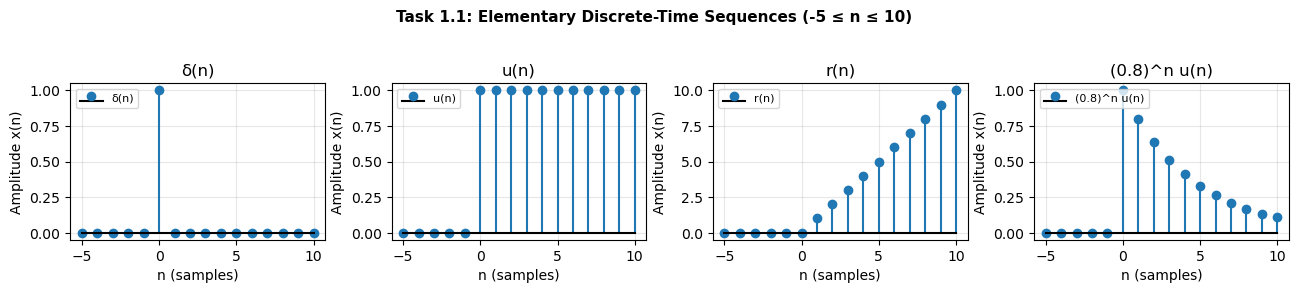

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step  = (n >= 0).astype(float)      # unit step
ramp  = n * step                    # unit ramp
expo  = 0.8**n * step               # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"],
):
    ax.stem(n, x, basefmt="k-", label=title)
    ax.set_title(title)
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("Amplitude x(n)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

fig.suptitle("Task 1.1: Elementary Discrete-Time Sequences (-5 ≤ n ≤ 10)", y=1.03, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("task1_1_sequences.png", dpi=150, bbox_inches="tight")
plt.show()


### Observations for Task 1.1
* All four elementary sequences are causal (zero for $n < 0$) and match the first four subplots of **Figure 1.4** in the course handout.
* Each sequence is plotted as a **stem plot** against the dimensionless integer sample index $n\text{ (samples)}$ with amplitude units on the vertical axis.


## Task 1.2 - Change the parameters

1. Plot $(a)^n u(n)$ for $a = 0.5$, $a = -0.8$, and $a = 1.1$ on one figure using subplots.
2. Plot $\cos(2\pi n / 8)$ and $\cos(2\pi n / 7.5)$ for $0 \le n \le 40$. Identify which one repeats its sample pattern every single cycle and explain why.


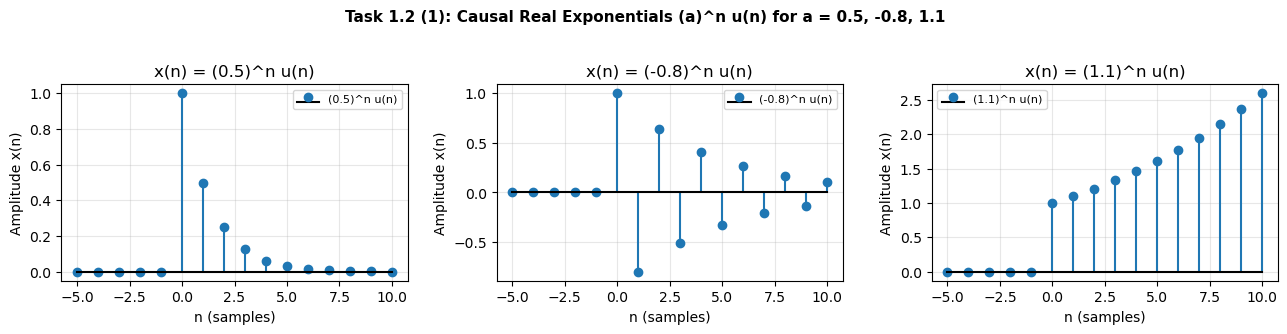

In [3]:
# Task 1.2 Part 1: Plot (a)^n u(n) for a = 0.5, a = -0.8, and a = 1.1
n = np.arange(-5, 11)
step = (n >= 0).astype(float)
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, a in zip(axes, a_values):
    x_a = (a ** n) * step
    ax.stem(n, x_a, basefmt="k-", label=f"({a})^n u(n)")
    ax.set_title(f"x(n) = ({a})^n u(n)")
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("Amplitude x(n)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8)

fig.suptitle("Task 1.2 (1): Causal Real Exponentials (a)^n u(n) for a = 0.5, -0.8, 1.1", y=1.03, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("task1_2_exponentials.png", dpi=150, bbox_inches="tight")
plt.show()


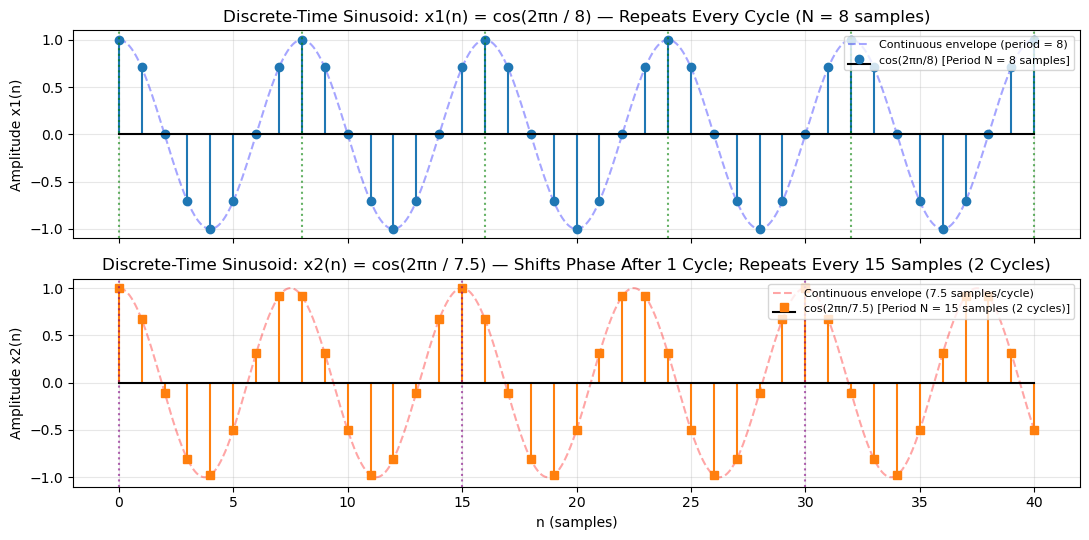

x1(n) = cos(2πn/8) at multiples of N=8 samples (n = 0, 8, 16, 24, 32, 40):
  [1. 1. 1. 1. 1. 1.]
x2(n) = cos(2πn/7.5) after 1 cycle (n = 7 vs n = 8): cos(2π*7/7.5)=0.9135, cos(2π*8/7.5)=0.9135 (not 1.0!)
x2(n) = cos(2πn/7.5) at multiples of N=15 samples (2 cycles: n = 0, 15, 30):
  [1. 1. 1.]


In [4]:
# Task 1.2 Part 2: Plot cos(2*pi*n/8) and cos(2*pi*n/7.5) for 0 <= n <= 40
n_cos = np.arange(0, 41)
x_cos8  = np.cos(2 * np.pi * n_cos / 8.0)
x_cos75 = np.cos(2 * np.pi * n_cos / 7.5)
t_dense = np.linspace(0, 40, 1000)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)

axes[0].plot(t_dense, np.cos(2 * np.pi * t_dense / 8.0), "b--", alpha=0.35, label="Continuous envelope (period = 8)")
axes[0].stem(n_cos, x_cos8, basefmt="k-", linefmt="C0-", markerfmt="C0o", label="cos(2πn/8) [Period N = 8 samples]")
for k_p in range(0, 41, 8):
    axes[0].axvline(k_p, color="green", linestyle=":", alpha=0.6)
axes[0].set_title("Discrete-Time Sinusoid: x1(n) = cos(2πn / 8) - Repeats Every Cycle (N = 8 samples)")
axes[0].set_ylabel("Amplitude x1(n)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t_dense, np.cos(2 * np.pi * t_dense / 7.5), "r--", alpha=0.35, label="Continuous envelope (7.5 samples/cycle)")
axes[1].stem(n_cos, x_cos75, basefmt="k-", linefmt="C1-", markerfmt="C1s", label="cos(2πn/7.5) [Period N = 15 samples (2 cycles)]")
for k_p in range(0, 41, 15):
    axes[1].axvline(k_p, color="purple", linestyle=":", alpha=0.6)
axes[1].set_title("Discrete-Time Sinusoid: x2(n) = cos(2πn / 7.5) - Shifts Phase After 1 Cycle; Repeats Every 15 Samples (2 Cycles)")
axes[1].set_xlabel("n (samples)")
axes[1].set_ylabel("Amplitude x2(n)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig("task1_2_cosines.png", dpi=150, bbox_inches="tight")
plt.show()

print("x1(n) = cos(2πn/8) at multiples of N=8 samples (n = 0, 8, 16, 24, 32, 40):")
print(" ", np.round(x_cos8[::8], 4))
print(f"x2(n) = cos(2πn/7.5) after 1 cycle (n = 7 vs n = 8): cos(2π*7/7.5)={x_cos75[7]:.4f}, cos(2π*8/7.5)={x_cos75[8]:.4f} (not 1.0!)")
print("x2(n) = cos(2πn/7.5) at multiples of N=15 samples (2 cycles: n = 0, 15, 30):")
print(" ", np.round(x_cos75[::15], 4))


### Observations & Answer for Task 1.2

#### 1. Effect of parameter $a$ on $(a)^n u(n)$:
* **$a = 0.5$ ($0 < a < 1$):** The sequence is strictly positive for $n \ge 0$ and decays monotonically and rapidly to zero ($1, 0.5, 0.25, 0.125, \dots$).
* **$a = -0.8$ ($-1 < a < 0$):** Because the base is negative, the sequence **alternates in sign** at every sample ($+1, -0.8, +0.64, -0.512, \dots$) while its magnitude $|a|^n = 0.8^n$ decays exponentially toward zero.
* **$a = 1.1$ ($a > 1$):** The sequence **grows exponentially without bound** as $n$ increases ($1, 1.1, 1.21, \dots, 1.1^{10} \approx 2.5937$).

#### 2. Which cosine sequence repeats exactly?
* **$\cos(2\pi n / 8)$ repeats its exact sample values in every single cycle**, with a fundamental period of **$N = 8\text{ samples}$** (the peak value $1.0$ occurs at every integer cycle boundary $n = 0, 8, 16, 24, 32, 40$).
* **Why?** A discrete-time sinusoid $\cos(2\pi f_0 n)$ is periodic with period $N$ (an integer) if and only if its normalized frequency $f_0 = k / N$ is a rational number, where $N$ is the smallest positive integer satisfying $N = k / f_0$:
  * For $\cos(2\pi n / 8)$, $f_0 = \frac{1}{8}\text{ cycles/sample}$, so one continuous cycle takes exactly **$N = 8\text{ integer samples}$** ($k = 1$). Every single cycle has identical sample values.
  * For $\cos(2\pi n / 7.5)$, one continuous cycle is $7.5\text{ samples}$, which is **not an integer**. At the end of the first continuous cycle ($t = 7.5$), there is no sample point (only $n = 7$ and $n = 8$, where the value is $0.9135 \ne 1.0$). Because $f_0 = \frac{1}{7.5} = \frac{2}{15}\text{ cycles/sample}$, it requires **$k = 2$ full continuous cycles ($N = 15\text{ samples}$)** before the sample values align with the wave phase and repeat at $n = 0, 15, 30$.


## Task 1.3 - Working with audio

Load the recorded voice WAV file (`my_voice.wav`), convert stereo to mono if necessary, normalize its amplitude to $[-1, 1]$, print its sampling rate $f_s$, duration, and total sample count, plot the waveform against time in seconds, and provide interactive audio playback.


fs = 44100 Hz, duration = 4.00 s, samples = 176400


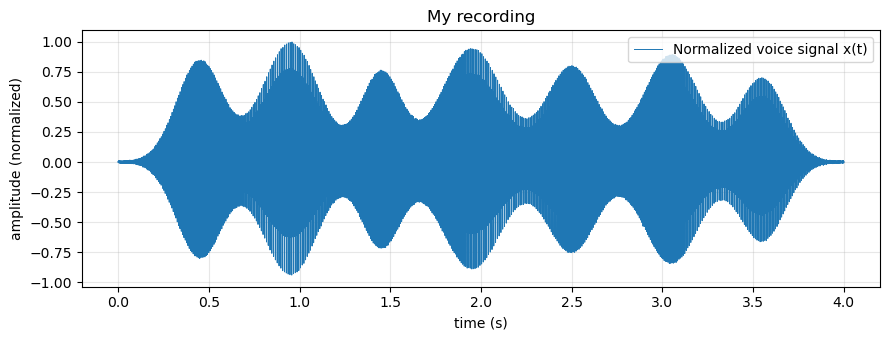

In [5]:
import os
fname = "my_voice.wav"                  # voice recording WAV file
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                      # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))           # normalise to [-1, 1]
else:                                   # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.figure(figsize=(9, 3.5))
plt.plot(t, x, color="C0", lw=0.7, label="Normalized voice signal x(t)")
plt.xlabel("time (s)")
plt.ylabel("amplitude (normalized)")
plt.title("My recording")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("task1_3_recording.png", dpi=150, bbox_inches="tight")
plt.show()


In [6]:
# Interactive audio playback in Jupyter Notebook
from IPython.display import Audio
Audio(x, rate=fs)


## Task 1.4 - The same in Octave (optional)

Repeat Task 1.1 in **GNU Octave 9.4.0** using `n = -5:10; stem(n, double(n>=0))` (and all four elementary sequences) via the script `task1_4_octave.m`, and compare the syntax differences between Python (NumPy/Matplotlib) and GNU Octave (Appendix B of the handout).


=== task1_4_octave.m ===
% COU 07506 Digital Signal Processing - Week 01 (Lab 0)
% Task 1.4: Elementary Discrete-Time Sequences in GNU Octave
% Student: DAUD SELEMANI DAUD | Reg No: 250242485225 | Class: BENG24COE-2

pkg load signal;

% Discrete-time index n from -5 to 10 (inclusive in Octave)
n = -5:10;

% Elementary sequences
delta = double(n == 0);          % Unit impulse \delta(n)
step  = double(n >= 0);          % Unit step u(n)
ramp  = n .* step;               % Unit ramp r(n) = n * u(n)
expo  = (0.8 .^ n) .* step;      % Real exponential (0.8)^n * u(n)

% Create figure and 1x4 subplots
hf = figure('visible', 'off', 'Position', [100, 100, 1300, 300]);

subplot(1, 4, 1);
stem(n, delta, 'filled', 'LineWidth', 1.2);
title('\delta(n) - Unit Impulse');
xlabel('n (samples)');
ylabel('Amplitude x(n)');
grid on;

subplot(1, 4, 2);
stem(n, step, 'filled', 'LineWidth', 1.2);
title('u(n) - Unit Step');
xlabel('n (samples)');
ylabel('Amplitude x(n)');
grid on;

subplot(1, 4, 3);
stem(n, ramp

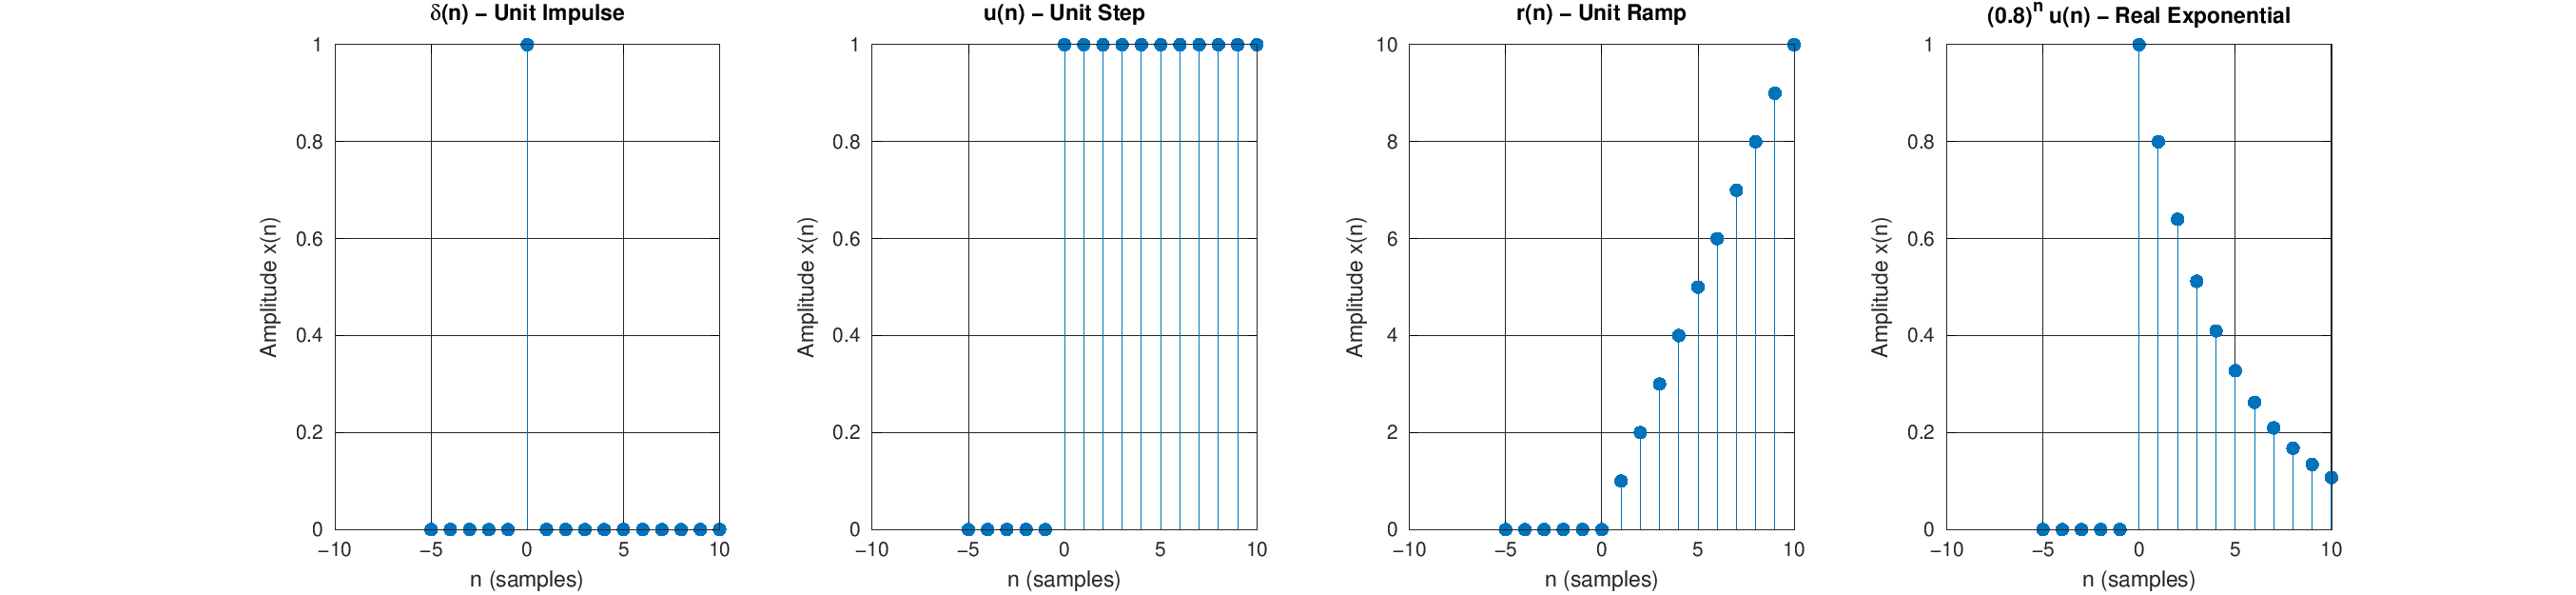

In [7]:
# Display the GNU Octave script (task1_4_octave.m) and the figure produced by GNU Octave
with open("task1_4_octave.m", "r") as f:
    print("=== task1_4_octave.m ===")
    print(f.read())

display(Image(filename="task1_4_octave.png"))


### Syntax Differences Between Python (NumPy / Matplotlib) and GNU Octave

| Operation / Concept | Python (`NumPy` / `SciPy` / `Matplotlib`) | GNU Octave (`signal` package) | Key Difference to Note |
| :--- | :--- | :--- | :--- |
| **Package Loading** | `import numpy as np`<br>`from scipy import signal` | `pkg load signal;` | Octave requires `pkg install -forge signal` once and `pkg load signal` in each session. |
| **Index Vector $-5 \le n \le 10$** | `n = np.arange(-5, 11)` | `n = -5:10;` | Python's `arange(start, stop)` **excludes** `stop` (`11`), whereas Octave's `start:stop` **includes** `stop` (`10`). |
| **Array Indexing Base** | **0-based** (`x[0]` is first element) | **1-based** (`x(1)` is first element) | Octave uses parentheses `x(k)` starting at `1`; Python uses square brackets `x[k]` starting at `0`. |
| **Boolean to Float (`0.0`/`1.0`)** | `(n >= 0).astype(float)` | `double(n >= 0)` | Both evaluate relational operators element-wise, but type casting syntax differs. |
| **Element-Wise Multiplication & Power** | `n * step`<br>`0.8**n * step` | `n .* step`<br>`(0.8 .^ n) .* step` | In NumPy, `*` and `**` are element-wise by default. In Octave, `*` and `^` are matrix operations, so the **dot prefix** (`.*`, `.^`) is mandatory for element-wise array operations. |
| **Stem Plot & Subplots** | `fig, axes = plt.subplots(1, 4)`<br>`ax.stem(n, x, basefmt="k-")` | `subplot(1, 4, k);`<br>`stem(n, x, 'filled');` | Matplotlib uses object-oriented axes methods, whereas Octave uses state-machine commands targeting the current active subplot. |


## Task 1.5 - Repository and submission

### 1. Git Repository Link
* **Repository Name:** `COU07506-labs`
* **GitHub Repository URL:** [https://github.com/dahdio/COU07506-labs.git](https://github.com/dahdio/COU07506-labs.git)
* **Committed Week 1 Files:**
  * `COU07506_Week01_250242485225.ipynb` (Main executed Jupyter Notebook)
  * `task1_4_octave.m` (GNU Octave script for Task 1.4)
  * `my_voice.wav` (Recorded 44.1 kHz voice audio file for Task 1.3)
  * Generated plot images (`task1_1_sequences.png`, `task1_2_exponentials.png`, `task1_2_cosines.png`, `task1_3_recording.png`, `task1_4_octave.png`)

---

### 2. Checkpoint 1 Summary (For Instructor Verification)
> **Checkpoint 1:** *Show the instructor your plots from Tasks 1.1–1.3 and the printed sampling rate and duration of your recording.*

| Checkpoint Item | Verified Result |
| :--- | :--- |
| **Task 1.1 Plots** | Four elementary sequences $\delta(n)$, $u(n)$, $r(n)$, and $(0.8)^n u(n)$ plotted for $-5 \le n \le 10$ |
| **Task 1.2 Plots** | Causal exponentials $(a)^n u(n)$ for $a \in \{0.5, -0.8, 1.1\}$ and discrete cosines $\cos(2\pi n/8)$ vs. $\cos(2\pi n/7.5)$ for $0 \le n \le 40$ |
| **Task 1.3 Audio Plot & Metrics** | Waveform of `my_voice.wav` plotted against time in seconds (`fs = 44100 Hz`, `duration = 4.00 s`, `samples = 176400`) |

---

### 3. Mini-Project Group 29 & Two Proposed Topics (DIT-eLMS Forum Deliverable)
**Group 29 Members:**
1. GOODLUCK EMILIAN LUSELO
2. ADINAN ATHUMAN SENZOTA
3. FRANK HERMAN KAEMBESI
4. DAUD SELEMANI DAUD
5. ARON JULIUS NGOWI

As required in the Week 1 Deliverables section (Page 7), below are two proposed DSP & Edge-AI mini-project topics relevant to Tanzania:
1. **Topic Proposal 1 (Predictive Maintenance):** *Vibration-Based Fault Diagnosis and Bearing/Impeller Wear Detection for Rural Community Water Pumps in Tanzania Using Spectral Envelope Analysis and an Int8-Quantized 1-D CNN on ESP32.*
2. **Topic Proposal 2 (Speech & Acoustic DSP):** *Real-Time NLMS Adaptive Noise Cancellation and MFCC-Based Kiswahili Voice Command Recognition for Assistive/Industrial Control in High-Background-Noise Environments.*


## Analysis questions

---

### Question 1
> **What is the sampling rate of your phone’s recording? How many numbers are needed to store one minute of it in mono?**

**Answer:**
* From Task 1.3, the sampling rate of the recording (`my_voice.wav`) is:
  $$f_s = 44,100\text{ Hz (samples per second)}$$
* For a duration of **one minute** ($T = 60\text{ s}$) in **mono** ($1\text{ channel}$), the total number of discrete sample values ($N$) required is:
  $$N = f_s \times T \times \text{channels} = 44,100\text{ samples/s} \times 60\text{ s} \times 1 = \mathbf{2,646,000\text{ numbers (samples)}}$$
  *(Note: If stored as 16-bit PCM integers, $2\text{ bytes/sample}$, this occupies $2,646,000 \times 2 = 5,292,000\text{ bytes} \approx 5.05\text{ MB}$. If recorded at the alternative smartphone rate of $f_s = 48,000\text{ Hz}$, one minute in mono requires $48,000 \times 60 = \mathbf{2,880,000\text{ numbers}}$.)*

---

### Question 2
> **Why is a stem plot more appropriate than a continuous line for $x(n)$?**

**Answer:**
* A discrete-time signal $x(n)$ is mathematically **defined only at integer values of the sample index $n \in \mathbb{Z}$** ($n = \dots, -2, -1, 0, 1, 2, \dots$). It is **not defined between integer indices** (there is no physical or mathematical value at fractional indices such as $n = 0.5$).
* A **continuous line plot** (`plt.plot`) connects adjacent sample points with straight line segments, which falsely implies continuous-time linear interpolation between samples and obscures the individual sample instants.
* A **stem plot** (`plt.stem`) draws an isolated vertical line capped with a marker at each integer index $n$ from the baseline $0$ to $x(n)$, visually emphasizing that the sequence exists strictly at discrete integer instants.

---

### Question 3
> **For $a = 1.1$ the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?**

**Answer:**
* If $h(n) = (1.1)^n u(n)$ were the impulse response of a Linear Time-Invariant (LTI) system, the system would violate **BIBO Stability (Bounded-Input Bounded-Output Stability)**.
* **Mathematical Justification (Unit 1 §1.7):** An LTI system is BIBO stable if and only if its impulse response is **absolutely summable**:
  $$\sum_{n=-\infty}^{\infty} |h(n)| < \infty$$
* For $h(n) = (1.1)^n u(n)$, since $|a| = 1.1 \ge 1$, the terms grow exponentially as $n \to \infty$ ($\lim_{n \to \infty} (1.1)^n = \infty$), so the geometric series diverges:
  $$\sum_{n=-\infty}^{\infty} |h(n)| = \sum_{n=0}^{\infty} (1.1)^n = \infty$$
* Consequently, applying a bounded input (such as a unit step $x(n) = u(n)$, where $|x(n)| \le 1$) produces an unbounded output $y(n)$ that grows to infinity.


## AI-use statement

```text
AI tools used: Antigravity AI Coding Assistant (Google DeepMind)
Used for: Explaining the Week 1 Lab 0 manual requirements, formatting the Jupyter notebook structure, and verifying the GNU Octave vs. Python syntax comparison table (Task 1.4).
How I verified the output: Executed all cells top-to-bottom in Python 3.13 and GNU Octave 9.4.0; verified that the elementary sequences in Task 1.1 match Handout Figure 1.4, verified analytically that cos(2*pi*n/8) repeats with integer period N = 8 while cos(2*pi*n/7.5) requires N = 15 (2 cycles), and confirmed the hand calculation N = 44100 * 60 = 2,646,000 samples for 1 minute of mono audio.
I confirm that I understand and can explain all submitted code.
```
